# Перепланирование MDVRP после отмены клиентов

Идея: не решать задачу заново, а взять вечернее решение $R^*$ и поправить его.

1. Вычеркнуть отменившихся клиентов из маршрутов. Решение сразу допустимо и не дороже $R^*$ (если $d$ — кратчайшие пути, выполняется неравенство треугольника).
2. Локальный поиск (перенос, обмен, слияние маршрутов), но стартуем только с клиентов затронутых маршрутов и их соседей. Остальная часть $R^*$ уже была оптимальной, менять там нечего.
3. Если есть время, несколько раз вынимаем группу клиентов рядом с изменениями и вставляем заново.

In [ ]:
import numpy as np
import random, time
import matplotlib.pyplot as plt

np.random.seed(0); random.seed(0)
K, A, M, n = 3, 4, 6, 60     # склады, машин на склад, макс клиентов на машину, клиенты
N = K + n                    # 0..K-1 склады, остальные клиенты
xy = np.random.rand(N, 2) * 100
xy[:K] = [[20, 30], [80, 30], [50, 80]]

# ориентированный граф: каждая вершина связана с 5 ближайшими, вес туда и обратно разный
E = np.linalg.norm(xy[:, None] - xy[None], axis=2)
W = np.full((N, N), np.inf)
np.fill_diagonal(W, 0)
for u in range(N):
    for v in np.argsort(E[u])[1:6]:
        W[u, v] = E[u, v] * np.random.uniform(1, 1.3)
        W[v, u] = min(W[v, u], E[u, v] * np.random.uniform(1, 1.3))

# кратчайшие пути
d = W.copy()
for m in range(N):
    d = np.minimum(d, d[:, [m]] + d[[m], :])
assert np.isfinite(d).all()

clients = list(range(K, N))
# 6 ближайших соседей каждого клиента
near = {c: sorted([v for v in clients if v != c], key=lambda v: d[c, v] + d[v, c])[:6] for c in clients}

Решение храним как список машин `[склад, [клиенты по порядку]]`, всего $K \cdot A$ машин. Пустой список — машина не выезжает.

In [2]:
def rcost(k, s):
    if not s:
        return 0
    return d[k, s[0]] + sum(d[a, b] for a, b in zip(s, s[1:])) + d[s[-1], k]

def cost(R):
    return sum(rcost(k, s) for k, s in R)

def copyR(R):
    return [[k, s[:]] for k, s in R]

def check(R, act):
    vis = [x for k, s in R for x in s]
    assert sorted(vis) == sorted(act) and all(len(s) <= M for k, s in R)

def insert(R, cl):
    # жадно вставляем каждого клиента в самое дешёвое место
    for c in cl:
        best = None
        for i, (k, s) in enumerate(R):
            if len(s) >= M:
                continue
            for p in range(len(s) + 1):
                delta = rcost(k, s[:p] + [c] + s[p:]) - rcost(k, s)
                if best is None or delta < best[0]:
                    best = (delta, i, p)
        R[best[1]][1].insert(best[2], c)
    return R

Локальный поиск. Для клиента `c` пробуем: перенести его в другое место (в свою машину, к соседу или в пустую машину), поменять местами с соседом, слить его маршрут с маршрутом соседа. Берём первый ход, который уменьшает стоимость, и добавляем клиентов изменённых машин обратно в очередь.

In [3]:
def try_move(R, where, c):
    i = where[c]
    k1, s1 = R[i]
    old1 = rcost(k1, s1)
    rest = [x for x in s1 if x != c]
    cand = {i} | {where[v] for v in near[c] if v in where} | {j for j, (k, s) in enumerate(R) if not s}

    # перенос
    for j in cand:
        k2, s2 = R[j]
        if j != i and len(s2) >= M:
            continue
        base = rest if j == i else s2
        for p in range(len(base) + 1):
            new = base[:p] + [c] + base[p:]
            if j == i:
                if rcost(k1, new) < old1 - 1e-9:
                    R[i][1] = new
                    return [i]
            elif rcost(k1, rest) + rcost(k2, new) < old1 + rcost(k2, s2) - 1e-9:
                R[i][1], R[j][1] = rest, new
                return [i, j]

    for v in near[c]:
        if v not in where or where[v] == i:
            continue
        j = where[v]
        k2, s2 = R[j]
        old = old1 + rcost(k2, s2)
        # обмен
        n1 = [v if x == c else x for x in s1]
        n2 = [c if x == v else x for x in s2]
        if rcost(k1, n1) + rcost(k2, n2) < old - 1e-9:
            R[i][1], R[j][1] = n1, n2
            return [i, j]
        # слияние двух маршрутов
        if len(s1) + len(s2) <= M:
            for a, b in ((i, j), (j, i)):
                m = R[a][1] + R[b][1]
                if rcost(R[a][0], m) < old - 1e-9:
                    R[a][1], R[b][1] = m, []
                    return [i, j]
    return None

def improve(R, queue):
    R = copyR(R)
    queue = set(queue)
    while queue:
        c = queue.pop()
        where = {x: i for i, (k, s) in enumerate(R) for x in s}
        changed = try_move(R, where, c)
        if changed:
            for j in changed:
                queue |= set(R[j][1])
    return R

def lns(R, centers, iters):
    # вынимаем клиента и 4 соседей, вставляем заново, оставляем если стало лучше
    best = copyR(R)
    act = {x for k, s in R for x in s}
    for _ in range(iters):
        c = random.choice(centers)
        out = [c] + [v for v in near[c] if v in act][:4]
        R2 = [[k, [x for x in s if x not in out]] for k, s in best]
        random.shuffle(out)
        R2 = improve(insert(R2, out), out)
        if cost(R2) < cost(best) - 1e-9:
            best = R2
    return best

def solve(cl, iters=5000):
    # решение с нуля
    R = insert([[k, []] for k in range(K) for _ in range(A)], cl)
    R = improve(R, cl)
    R = lns(R, cl, iters)
    return improve(R, cl)

## Вечер: решение для всех клиентов

Считаем долго, это время в утренний пересчёт не входит.

In [4]:
t0 = time.perf_counter()
R_star = solve(clients)
t_evening = time.perf_counter() - t0
check(R_star, clients)
print(f"R*: {cost(R_star):.1f}, время {t_evening:.1f} с")

R*: 1118.3, время 3.6 с


## Утро: 6 клиентов отменили доставку

In [5]:
removed = random.sample(clients, 6)
active = [c for c in clients if c not in removed]

t0 = time.perf_counter()
# шаг 1: вычеркнуть
R0 = [[k, [x for x in s if x not in removed]] for k, s in R_star]
t1 = time.perf_counter()

# шаг 2: очередь = клиенты затронутых машин + клиенты, у которых они в соседях
hit = [i for i, (k, s) in enumerate(R_star) if set(s) & set(removed)]
base = {x for i in hit for x in R0[i][1]}
queue = base | {c for c in active if set(near[c]) & base}
R1 = improve(R0, queue)
t2 = time.perf_counter()

# шаг 3: LNS вокруг изменений
R2 = lns(R1, list(queue), 150)
t3 = time.perf_counter()

check(R0, active); check(R2, active)
print("затронуто машин:", len(hit), "из", sum(1 for k, s in R_star if s))
print("клиентов в очереди:", len(queue), "из", len(active))

затронуто машин: 6 из 10
клиентов в очереди: 41 из 54


In [6]:
print(f"R*  (вечер)          {cost(R_star):.1f}")
print(f"R0  (вычеркнули)     {cost(R0):.1f}   {(t1 - t0) * 1e3:.2f} мс")
print(f"R1  (+ лок. поиск)   {cost(R1):.1f}   {(t2 - t0) * 1e3:.1f} мс")
print(f"R2  (+ LNS)          {cost(R2):.1f}   {(t3 - t0):.2f} с")
print(f"для сравнения, вечерний расчёт шёл {t_evening:.1f} с")

R*  (вечер)          1118.3
R0  (вычеркнули)     1097.9   0.14 мс
R1  (+ лок. поиск)   1021.8   7.5 мс
R2  (+ LNS)          990.5   0.14 с
для сравнения, вечерний расчёт шёл 3.6 с


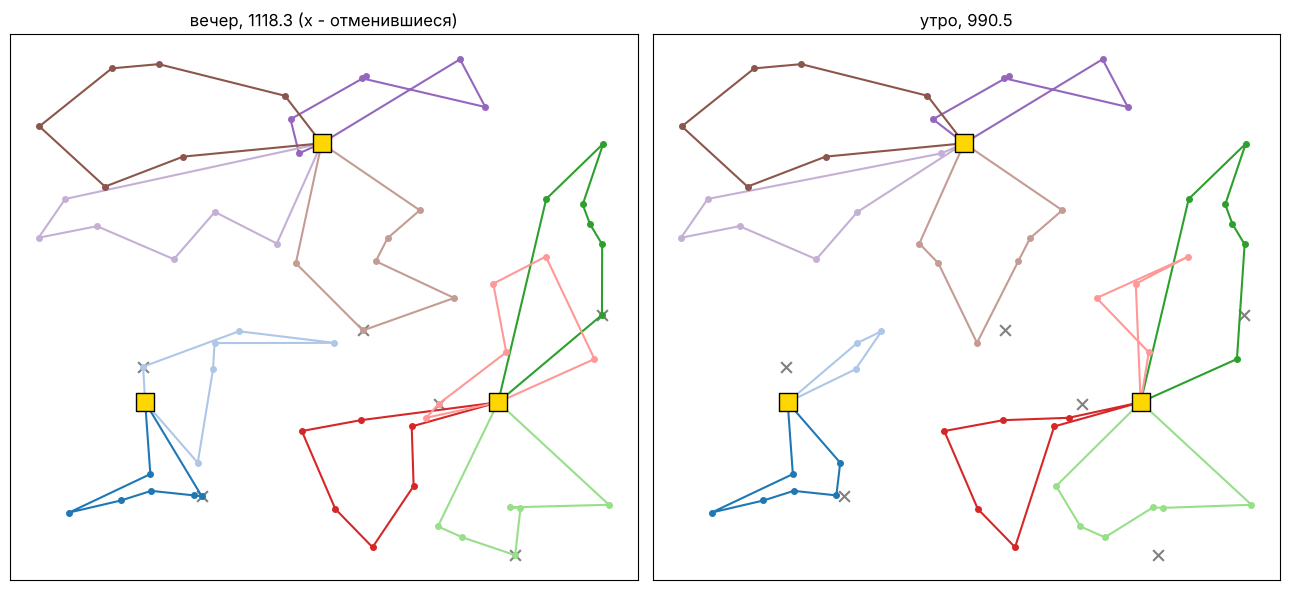

In [7]:
def plot(R, title, ax):
    for i, (k, s) in enumerate(R):
        path = [k] + s + [k]
        if s:
            ax.plot(xy[path, 0], xy[path, 1], "-o", ms=4, color=plt.cm.tab20(i))
    ax.scatter(*xy[removed].T, marker="x", c="grey", s=60)
    ax.scatter(*xy[:K].T, marker="s", c="gold", edgecolors="k", s=150, zorder=3)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
plot(R_star, f"вечер, {cost(R_star):.1f} (x - отменившиеся)", ax[0])
plot(R2, f"утро, {cost(R2):.1f}", ax[1])
plt.tight_layout(); plt.show()